# Metoda gradientów sprzężonych

## Funkcje z zajęć

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter

In [2]:
def gd(A, b, x0, eps=1e-6, max_iter=20_000,
       keep_history=True, time_limit=np.inf):
    start = perf_counter()

    x = np.array(x0, dtype=float)
    r = b - A @ x  # residuum w punkcie początkowym
    p = r

    X = [x.copy()] if keep_history else []
    R = [np.linalg.norm(r)]
    T = [0.]

    status = "limit iteracji"
    for k in range(max_iter):
        if not np.isfinite(R[-1]):
            status = "nieskończone residuum"
            break
        if R[-1] <= eps:
            break
        if perf_counter() - start >= time_limit:
            status = "limit czasu"
            break
        
        Ap = A @ p
        alpha = (r @ r) / (p @ Ap)  # dokładny krok

        x = x + alpha * p  # nowy punkt
        r = r - alpha * Ap  # aktualizacja residuum
        p = r 

        if keep_history:
            X.append(x.copy())
        R.append(np.linalg.norm(r))
        T.append(perf_counter() - start)
    if R[-1] <= eps:
        status = "OK"
    return {"x": x, "X": np.array(X), "R": np.array(R),
            "T": np.array(T), "status": status}

In [3]:
def cg(A, b, x0, eps=1e-6, max_iter=20_000,
       keep_history=True, time_limit=np.inf):
    start = perf_counter()

    x = np.array(x0, dtype=float)
    r = b - (A @ x0)
    p = r

    X = [x.copy()] if keep_history else []
    R = [np.linalg.norm(r)]
    T = [0.]

    status = "limit iteracji"
    for k in range(max_iter):
        if not np.isfinite(R[-1]):
            status = "nieskończone residuum"
            break
        if R[-1] <= eps:
            break
        if perf_counter() - start >= time_limit:
            status = "limit czasu"
            break
        
        Ap = A @ p
        alpha = (r @ r) / (p @ Ap)  # dokładny krok

        x = x + alpha * p  # nowy punkt
        r_next = r - alpha * Ap  # nowe residuum

        beta = (r_next @ r_next) / (r @ r)  # współczynnik poprawki

        p = r_next + beta * p  # nowy kierunek
        r = r_next

        if keep_history:
            X.append(x.copy())
        R.append(np.linalg.norm(r))
        T.append(perf_counter() - start)
    if R[-1] <= eps:
        status = "OK"
    return {"x": x, "X": np.array(X), "R": np.array(R),
            "T": np.array(T), "status": status}

In [4]:
def positive(values):
    values = np.asarray(values)
    return np.where(values > 0, values, np.nan)


def energy(A, x, x_star):
    e = x - x_star
    return e @ A @ e


A = np.diag([1., 40.])
x_star = np.ones(2)
result = cg(A, A @ x_star, np.zeros(2), eps=1e-10)
assert np.allclose(result["x"], x_star) and len(result["R"]) - 1 == 2

In [5]:
# GD z Lab 1 (inna nazwa, bo gd z Lab 3 jest dla funkcji kwadratowej)
def gd_nonlinear(f, grad_f, x0, step, eps=1e-5, max_iter=20_000):
    x_k = np.array(x0, dtype=float)
    g = grad_f(x_k)  # gradient
    g_norm = np.linalg.norm(g)
    X = [x_k.copy()]
    G = [g_norm]
    status = "limit iteracji"
    for k in range(max_iter):
        if not np.isfinite(g_norm) or g_norm <= eps:  # warunek stopu
            break
        p = -g  # kierunek

        def phi(alpha):
            return f(x_k + alpha * p)

        try:
            alpha_star = step(phi, -np.dot(g, g))
        except RuntimeError:  # procedura z Lab 1 nie znalazła kroku
            status = "niepowodzenie doboru kroku"
            break
        x_k = x_k + alpha_star * p  # nowy punkt
        X.append(x_k.copy())
        g = grad_f(x_k)  # gradient
        g_norm = np.linalg.norm(g)
        G.append(g_norm)
    if not np.isfinite(g_norm):
        status = "brak skończonej normy"
    elif g_norm <= eps:  # warunek stopu
        status = "OK"
    return np.array(X), np.array(G), status

In [6]:
def golden(phi, a, b, tol=1e-6):
    r = (np.sqrt(5) - 1) / 2
    width_start = b - a
    width = width_start
    c = a + (1 - r) * (b - a)
    d = a + r * (b - a)
    fc = phi(c)
    fd = phi(d)
    for _ in range(100):
        if b - a <= tol * width_start:
            break
        if fc <= fd:
            b = d
            d = c
            fd = fc
            width = b - a
            c = a + (1-r) * width
            fc = phi(c)
        else:
            a = c
            c = d
            fc = fd
            width = b - a
            d = a + r * width
            fd = phi(d)
    return c if fc <= fd else d


def golden_fixed(phi, a=0., b=1., tol=1e-6):
    phia = phi(a)
    r = (np.sqrt(5) - 1) / 2
    for _ in range(100):
        c = a + (1 - r) * (b - a)
        if phi(c) < phia:  # znaleziono ścisły spadek
            return golden(phi, a, b, tol)
        b = c
    raise RuntimeError("Nie znaleziono kroku zmniejszającego funkcję")

In [7]:
def backtracking(phi, dphi0, alpha0=1., rho=0.5, c1=0.1):
    phi0 = phi(0.)
    alpha = alpha0
    for _ in range(100):
        if phi(alpha) <= phi0 + c1 * alpha * dphi0:  # warunek Armijo
            return alpha
        alpha = rho * alpha
    raise RuntimeError("Nie znaleziono kroku Armijo")

In [8]:
def rosen_n(x):
    x = np.asarray(x, dtype=float)
    return np.sum((1 - x[:-1])**2 + 100 * (x[1:] - x[:-1]**2)**2)


def grad_rosen_n(x):
    x = np.asarray(x, dtype=float)
    t = x[1:] - x[:-1]**2
    g = np.zeros_like(x)
    g[:-1] = 2 * (x[:-1] - 1) - 400 * x[:-1] * t
    g[1:] += 200 * t
    return g


assert np.isclose(rosen_n(np.ones(40)), 0.)
assert np.allclose(grad_rosen_n(np.ones(40)), 0.)

## 1. To samo uwarunkowanie, różne widma — GD i CG

Wróć do zadania 2 z pracy domowej 2 (Lab 2). Dla obu macierzy porównaj GD z CG, zachowując te same dane, punkty startowe, tolerancję i limit iteracji.

Dla każdej macierzy pokaż na wspólnym wykresie względny błąd energetyczny obu metod. Podaj liczbę iteracji, końcową normę residuum i przyczynę zakończenia. Wyjaśnij wpływ rozkładu wartości własnych na wyniki i związek liczby różnych wartości własnych z liczbą kroków CG w arytmetyce dokładnej.

In [9]:
# dane i wyniki GD z zadania 2 pracy domowej 2 (zapisane tam do pliku pd2_zad2.npz)
data = np.load("pd2_zad2.npz")
x_star = data["x_star"]
x0 = data["x0"]
eps = 1e-6  # ta sama tolerancja i limit iteracji co w PD2
max_iter = 20_000

labels = {"A1": "A₁: równomierne 1…100", "A2": "A₂: 1, 10, …, 10, 100"}
pd2 = {}
for key in labels:
    pd2[key] = {name: data[f"{key}_{name}"] for name in ["values", "A", "b", "X", "R", "ratio"]}
    R = pd2[key]["R"]
    status = "OK" if R[-1] <= eps else "limit iteracji"
    print(f"{labels[key]:22s} | GD: {len(R) - 1} iteracji, końcowe ‖r‖ = {R[-1]:.2e}, status {status}")

A₁: równomierne 1…100  | GD: 705 iteracji, końcowe ‖r‖ = 9.79e-07, status OK
A₂: 1, 10, …, 10, 100  | GD: 711 iteracji, końcowe ‖r‖ = 9.78e-07, status OK


In [ ]:
zad1 = {}
print("macierz                | metoda | kroki | końcowe ‖r‖ | końcowe Eₖ/E₀ | status | różne wartości własne")
for key in labels:
    A = pd2[key]["A"]
    b = pd2[key]["b"]
    distinct = len(np.unique(pd2[key]["values"]))  # liczba różnych wartości własnych

    # GD: wyniki z PD2 (wczytane wyżej z pliku)
    R = pd2[key]["R"]
    ratio = pd2[key]["ratio"]
    status = "OK" if R[-1] <= eps else "limit iteracji"
    print(f"{labels[key]:22s} | GD     | {len(R) - 1:5d} | {R[-1]:11.2e} | {ratio[-1]:13.2e} | {status:6s} | {distinct}")

    # CG: te same dane, punkt startowy, tolerancja i limit iteracji
    result = cg(A, b, x0, eps=eps, max_iter=max_iter)
    E = np.array([energy(A, x, x_star) for x in result["X"]]) 
    zad1[key] = {"GD": ratio, "CG": E / E[0]}
    print(f"{labels[key]:22s} | CG     | {len(result['R']) - 1:5d} | {result['R'][-1]:11.2e} | "
          f"{E[-1] / E[0]:13.2e} | {result['status']:6s} | {distinct}")

macierz                | metoda | kroki | końcowe ‖r‖ | końcowe Eₖ/E₀ | status | różne wartości własne
A₁: równomierne 1…100  | GD     |   705 |    9.79e-07 |      1.03e-16 | OK     | 100
A₁: równomierne 1…100  | CG     |    56 |    8.33e-07 |      4.93e-18 | OK     | 100
A₂: 1, 10, …, 10, 100  | GD     |   711 |    9.78e-07 |      4.51e-16 | OK     | 3
A₂: 1, 10, …, 10, 100  | CG     |     3 |    3.23e-12 |      1.04e-28 | OK     | 3


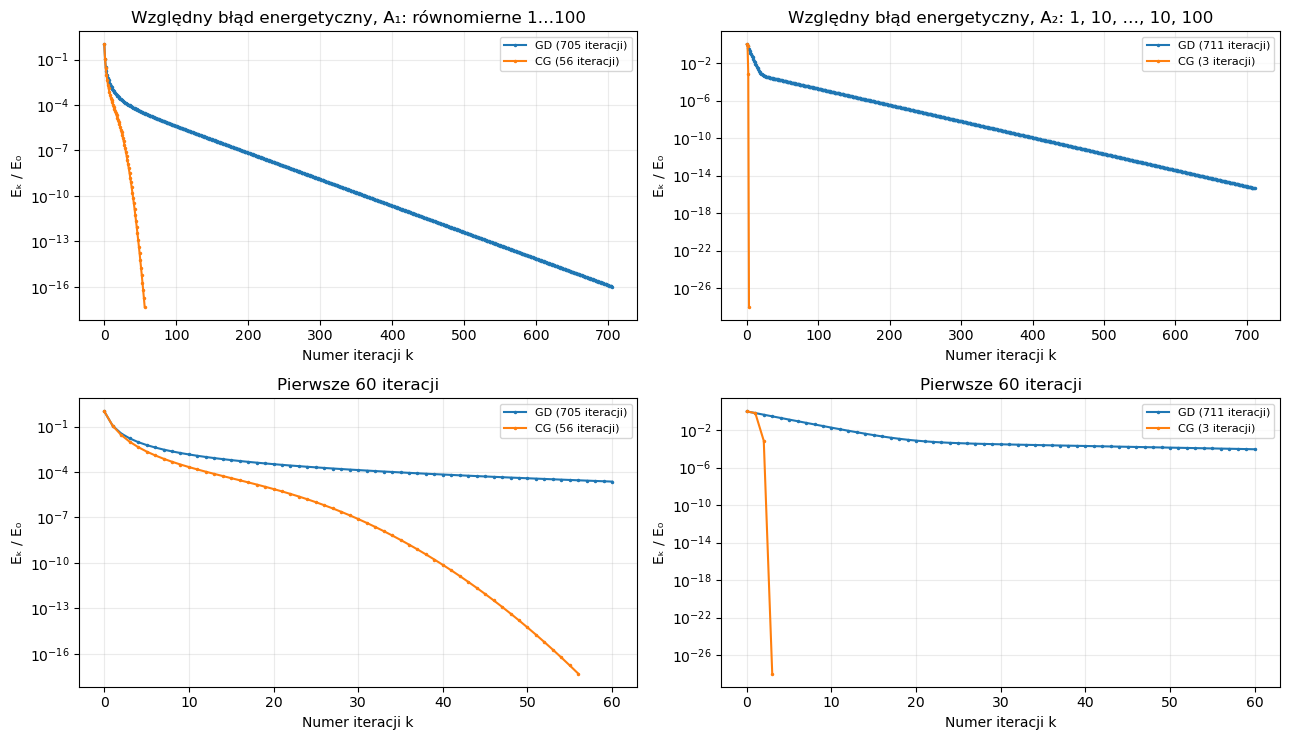

In [11]:
plot = plt.subplots(2, 2, figsize=(13, 7.5))
fig = plot[0]
axes = plot[1]
for j, key in enumerate(labels):
    for ax, k_max in [(axes[0, j], None), (axes[1, j], 61)]:  # cały przebieg i pierwsze 60 iteracji
        for name in ["GD", "CG"]:
            ratio = zad1[key][name][:k_max]
            ax.semilogy(positive(ratio), ".-", markersize=3, label=f"{name} ({len(zad1[key][name]) - 1} iteracji)")
        ax.set(xlabel="Numer iteracji k", ylabel="Eₖ / E₀")
    axes[0, j].set(title=f"Względny błąd energetyczny, {labels[key]}")
    axes[1, j].set(title="Pierwsze 60 iteracji")
for ax in axes.flat:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

**Wnioski:**
- Wszystkie cztery przebiegi zakończyły się statusem OK. $A_1$: GD 705 iteracji, CG 56. $A_2$: GD 711, CG 3. Końcowe $\|r\|_2$: GD $\approx9{,}8\cdot10^{-7}$ dla obu macierzy, CG $8{,}33\cdot10^{-7}$ dla $A_1$ i $3{,}23\cdot10^{-12}$ dla $A_2$.
- To samo $\kappa=100$, a wpływ widma jest zupełnie inny dla obu metod. GD prawie go nie zauważa (705 i 711 iteracji), bo jego tempo zależy od $\kappa$. CG dla $A_1$ potrzebuje 56 kroków, a dla $A_2$ tylko 3.
- $A_1$ ma 100 różnych wartości własnych rozłożonych równomiernie. CG zbiega stopniowo, ale i tak ma ok. 12,6 razy mniej iteracji niż GD (liczba kroków rośnie jak $\sqrt\kappa$, a nie jak $\kappa$). Na wykresie GD po początkowym spadku ma stałe nachylenie, a krzywa CG opada coraz szybciej.
- $A_2$ ma tylko 3 różne wartości własne (1, 10, 100) i CG kończy dokładnie po 3 krokach. 98 składowych z $\lambda=10$ ma tę samą wartość własną i ten sam błąd początkowy, więc zachowują się jak jedna współrzędna. Zadanie jest w praktyce trójwymiarowe, a CG z $A$-sprzężonymi kierunkami potrzebuje wtedy najwyżej 3 kroków.
- Ogólnie w arytmetyce dokładnej CG kończy po co najwyżej tylu krokach, ile jest różnych wartości własnych. Dla $A_1$ daje to granicę 100 kroków, ale tolerancja $10^{-6}$ została osiągnięta już po 56, więc metoda zatrzymała się wcześniej.
- Błędy zaokrągleń nie zmieniły liczby kroków dla $A_2$ (3 kroki, 3 wartości własne). Widać je tylko w tym, że po 3. kroku residuum nie jest dokładnie zerem, tylko $3{,}23\cdot10^{-12}$ ($E_3/E_0\approx10^{-28}$). Dla $A_1$ ich wpływu nie da się tu ocenić, bo CG kończy przez tolerancję przed 100. krokiem.

## 2. Nieliniowe CG — Rosenbrock w 40 wymiarach

Korzystając z zadania **D.L.3.2** z kartki `lab_3_D.pdf`, zaimplementuj metody Fletchera–Reevesa (FR) i Polaka–Ribière’a (PR). Przyjmij oznaczenie $\nabla f_k=\nabla f(x_k)$. Gradient w każdym nowym punkcie obliczaj bezpośrednio. **Jeżeli otrzymany kierunek nie jest kierunkiem spadku, zastąp go kierunkiem największego spadku.**

Dokładną minimalizację w kierunku z kartki zastąp **jedną wybraną** procedurą z Lab 1: backtrackingiem albo `golden_fixed`. Użyj tej samej procedury i parametrów z Lab 1 dla GD, FR i PR. Pamiętaj, że dla kierunku $p_k$ pochodna funkcji $\phi(\alpha)=f(x_k+\alpha p_k)$ wynosi $\phi'(0)=(\nabla f_k)^\top p_k$.

Porównaj te trzy metody dla funkcji Rosenbrocka z zadania 3 z pracy domowej 1 (Lab 1), przy $n=40$ i wspólnym starcie $x_0=(-1.2,\ldots,-1.2)$. Przyjmij limit 20 000 iteracji i warunek stopu
$$
\frac{\|\nabla f_k\|_2}{\sqrt{40}}\le10^{-5}.
$$

Na dwóch wspólnych wykresach przedstaw $f(x_k)/39$ oraz $\|\nabla f_k\|_2/\sqrt{40}$. W tabeli podaj liczbę iteracji i wywołań funkcji oraz gradientu podczas optymalizacji, końcową wartość funkcji, normę gradientu i przyczynę zakończenia. Omów skuteczność i koszt metod: czy mniej iteracji oznacza mniej obliczeń? Czy uzyskane wartości funkcji są bliskie minimum globalnemu $0$?

Osiągnięcie limitu iteracji lub niepowodzenie doboru kroku również jest wynikiem eksperymentu — odnotuj je i omów. Nie zakładaj z góry, która metoda okaże się najlepsza.

In [ ]:
# nieliniowe CG z zadania D.L.3.2: method="FR" (Fletcher–Reeves) albo "PR" (Polak–Ribière)
def cg_nonlinear(f, grad_f, x0, step, method="FR", eps=1e-5, max_iter=20_000):
    x_k = np.array(x0, dtype=float)
    g = grad_f(x_k)  # gradient
    g_norm = np.linalg.norm(g)
    p = -g  # p₀ = r₀ = −∇f(x₀)
    X = [x_k.copy()]
    G = [g_norm]
    status = "limit iteracji"
    for k in range(max_iter):
        if not np.isfinite(g_norm) or g_norm <= eps:  # warunek stopu
            break
        dphi0 = g @ p  # φ'(0) = ∇f_kᵀ p_k
        if dphi0 >= 0:  # to nie jest kierunek spadku -> kierunek największego spadku
            p = -g
            dphi0 = -(g @ g)

        def phi(alpha):
            return f(x_k + alpha * p)

        try:
            alpha_k = step(phi, dphi0)
        except RuntimeError: 
            status = "niepowodzenie doboru kroku"
            break
        x_k = x_k + alpha_k * p  # nowy punkt
        X.append(x_k.copy())
        g_next = grad_f(x_k)  # gradient w nowym punkcie
        if method == "FR":
            beta = (g_next @ g_next) / (g @ g)
        else:  # PR
            beta = (g_next @ (g_next - g)) / (g @ g)
        p = -g_next + beta * p  # nowy kierunek
        g = g_next
        g_norm = np.linalg.norm(g)
        G.append(g_norm)
    if not np.isfinite(g_norm):
        status = "brak skończonej normy"
    elif g_norm <= eps:  # warunek stopu
        status = "OK"
    return np.array(X), np.array(G), status


#dla funkcji kwadratowej z dokładnym krokiem FR i PR dają CG2 (2 kroki dla diag(1, 40))
A = np.diag([1., 40.])
b = A @ np.ones(2)


def exact_step(phi, dphi0):  # dla funkcji kwadratowej φ(α) = φ(0) + φ'(0)α + cα²/2
    c = 2 * (phi(1.) - phi(0.) - dphi0)
    return -dphi0 / c


for method in ["FR", "PR"]:
    X, G, status = cg_nonlinear(lambda x: x @ A @ x / 2 - b @ x, lambda x: A @ x - b,
                                np.zeros(2), exact_step, method, eps=1e-10)
    assert status == "OK" and len(X) - 1 == 2 and np.allclose(X[-1], np.ones(2))

In [ ]:
n = 40
step = backtracking  # jedna procedura dla GD, FR i PR

Dobór kroku: backtracking z parametrami z Lab 1 ($\alpha_0=1$, $\rho=0{,}5$, $c_1=0{,}1$).

In [ ]:
def count_restarts(X):
    restarts = 0
    for k in range(1, len(X) - 1):
        g = grad_rosen_n(X[k])
        d = X[k + 1] - X[k]
        if -(g @ d) >= (1 - 1e-12) * np.linalg.norm(g) * np.linalg.norm(d):
            restarts += 1
    return restarts


def run_method(name):
    x0 = np.full(n, -1.2)
    calls_f = 0
    calls_grad = 0

    def counted_f(x):
        nonlocal calls_f
        calls_f += 1
        return rosen_n(x)

    def counted_grad(x):
        nonlocal calls_grad
        calls_grad += 1
        return grad_rosen_n(x)

    # warunek ‖∇f‖/√n ≤ 1e-5 to to samo co ‖∇f‖ ≤ 1e-5·√n
    if name == "GD":
        result = gd_nonlinear(counted_f, counted_grad, x0, step, eps=1e-5 * np.sqrt(n), max_iter=20_000)
    else:
        result = cg_nonlinear(counted_f, counted_grad, x0, step, method=name,
                              eps=1e-5 * np.sqrt(n), max_iter=20_000)
    X = result[0]
    G = result[1]
    status = result[2]
    values = np.array([rosen_n(x) for x in X])  # f(x_k) do wykresu: liczone po optymalizacji, poza licznikiem
    restarts = "—" if name == "GD" else str(count_restarts(X))
    history[name] = (values, G)
    print(f"{name:6s} | {len(X) - 1:5d} | {calls_f:11d} | {calls_grad:12d} | {calls_f / (len(X) - 1):9.1f} | "
          f"{restarts:>8s} | {values[-1]:9.2e} | {G[-1] / np.sqrt(n):9.3e} | "
          f"{np.max(np.abs(X[-1] - 1)):8.2e} | {status}")


history = {}
print("metoda | kroki | wywołania f | wywołania ∇f | f na krok | restarty | f końcowe | ‖∇f‖/√n   | max|x-1| | status")
for name in ["GD", "FR", "PR"]:
    run_method(name)

metoda | kroki | wywołania f | wywołania ∇f | f na krok | restarty | f końcowe | ‖∇f‖/√n   | max|x-1| | status


GD     | 15158 |      178381 |        15159 |      11.8 |        — |  2.46e-09 | 9.932e-06 | 8.60e-05 | OK


FR     |  6488 |      116199 |         6489 |      17.9 |        0 |  4.04e-12 | 9.996e-06 | 2.52e-07 | OK
PR     |   240 |        2786 |          241 |      11.6 |       31 |  9.56e-10 | 9.267e-06 | 5.37e-05 | OK


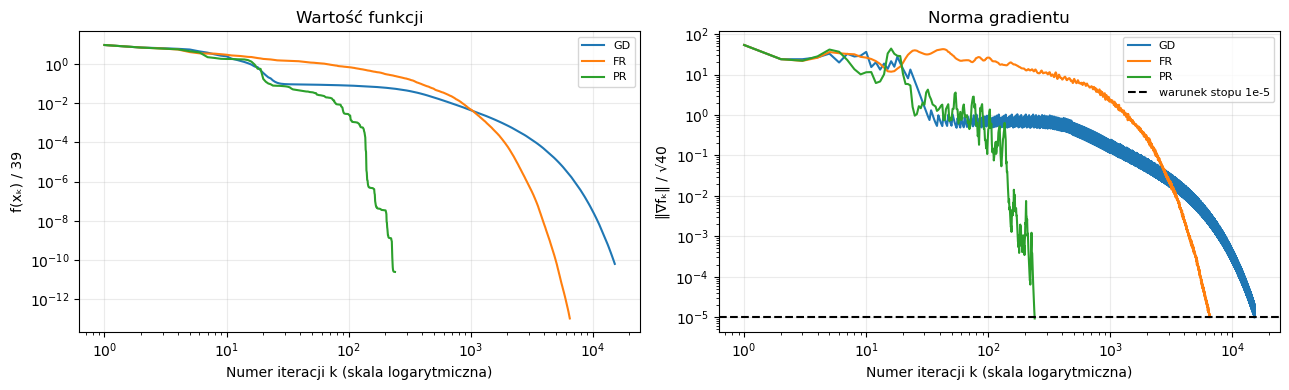

In [ ]:
plot = plt.subplots(1, 2, figsize=(13, 4))
fig = plot[0]
ax_value, ax_grad = plot[1]
for name in history:
    values, G = history[name]
    k = np.arange(1, len(G))  # oś k w skali log (od k = 1), żeby było widać też krótki przebieg PR
    ax_value.loglog(k, values[1:] / (n - 1), label=name)
    ax_grad.loglog(k, G[1:] / np.sqrt(n), label=name)
ax_grad.axhline(1e-5, color="k", linestyle="--", label="warunek stopu 1e-5")
ax_value.set(xlabel="Numer iteracji k (skala logarytmiczna)", ylabel="f(xₖ) / 39", title="Wartość funkcji")
ax_grad.set(xlabel="Numer iteracji k (skala logarytmiczna)", ylabel="‖∇fₖ‖ / √40", title="Norma gradientu")
for ax in (ax_value, ax_grad):
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

**Wnioski:**
- Wszystkie trzy metody zakończyły się statusem OK - żadna nie doszła do limitu 20 000 iteracji i dobór kroku ani razu nie zawiódł. GD potrzebował 15 158 iteracji, FR 6 488, a PR 240.
- Końcowe $f$ to $2{,}46\cdot10^{-9}$ (GD), $4{,}04\cdot10^{-12}$ (FR) i $9{,}56\cdot10^{-10}$ (PR), a $\max_i|x_i-1|\le8{,}6\cdot10^{-5}$, więc wszystkie wyniki są bliskie minimum globalnemu $0$ w $(1,\ldots,1)$.
- Koszt: gradient liczymy raz na iterację (15 159, 6 489 i 241 wywołań), a większość obliczeń to wywołania $f$ w backtrackingu: 178 381 (GD), 116 199 (FR) i 2 786 (PR).
- Mniej iteracji nie oznacza proporcjonalnie mniej obliczeń. FR ma 2,3 razy mniej iteracji niż GD, ale tylko 1,5 razy mniej wywołań $f$, bo jedna iteracja FR to średnio 17,9 wywołania $f$, a GD 11,8 (backtracking zaczyna od $\alpha_0=1$ i w FR musi skracać krok więcej razy). PR ma 11,6 wywołania na iterację, czyli podobnie jak GD, więc ma ok. 63 razy mniej iteracji i 64 razy mniej wywołań $f$ niż GD.
- FR i PR różnią się tylko wzorem na $\beta$, a w tym eksperymencie PR potrzebował 27 razy mniej iteracji. Na wykresie FR przez pierwsze ok. 1000 iteracji ma nawet większe $f$ niż GD i dopiero potem go wyprzedza.
- Restart w FR nie zadziałał ani razu, a w PR 31 razy na 240 iteracji. Przy dokładnej minimalizacji w kierunku byłoby $\nabla f_{k+1}^\top p_k=0$ i nowy kierunek zawsze byłby kierunkiem spadku. Backtracking nie jest dokładny, więc czasem wychodzi $\nabla f_k^\top p_k\ge0$. Bez restartu warunek Armijo z $\phi'(0)\ge0$ nie gwarantowałby spadku funkcji.